In [1]:
!pip install nibabel

In [2]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [3]:
h = nib.load('s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


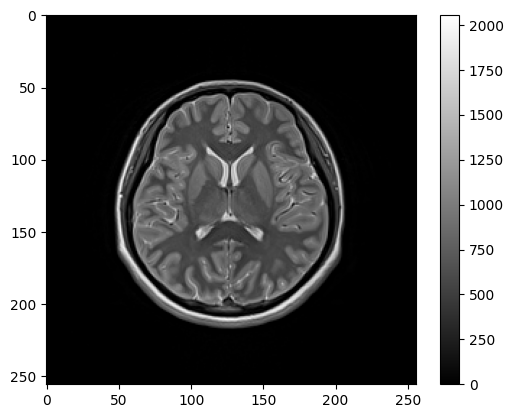

In [4]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

최종 임계값: 412.83584834444696


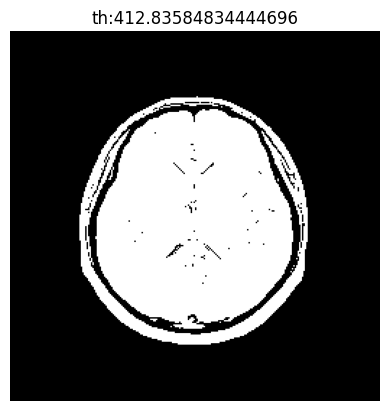

In [5]:
T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
while dT > esp:
  #현재 임계값기준으로 두그룹 나누기
  G1 = f[f > T[-1]]
  G2 = f[f <= T[-1]]
  #각그룹의 평균
  m1 = np.mean(G1)
  m2 = np.mean(G2)
  #새로운 임계값
  T.append((m1 + m2) / 2)
  # 이전 임계값과의 차이
  dT = np.abs(T[-1] - T[-2])

print('최종 임계값:', T[-1])

##

bmsk = f>T[-1]
plt.imshow(bmsk,cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

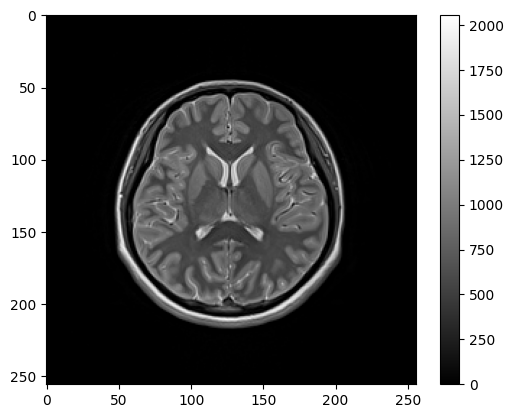

In [6]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

[ 64. 128.]
[  5.91248043 768.93253625]
[ 13.3779618  806.97810069]
[ 14.87874927 810.79294742]
최종 중심값: [ 15.03283183 811.16716123]


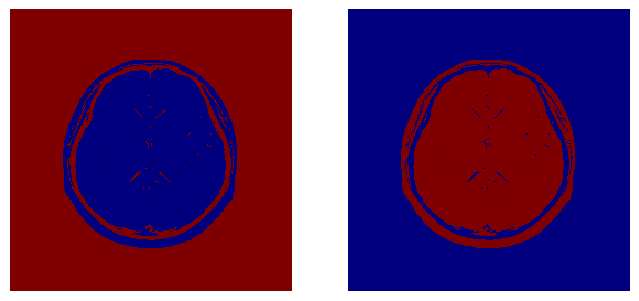

In [7]:
m_vals = np.array([64., 128.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1
cmap = np.argmin(c,axis=-1)
while E>eps:
  print(m_vals)
  ##
  # your k-means clustering algorithm #
  for i in range(len(m_vals)): #각 필섹과 각 중심의 밝기 차이 계산
    c[:,:,i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c,axis=-1) #가장 가까운 중심의 그룹으로 배정

  for i in range(len(m_vals)): #각 그룸의 평균으로 그룹중심갱신
    if np.any(cmap==i):
      m_vals_new[i] = np.mean(f[cmap==i])
    else:
      m_vals_new[i] = 0

  E = np.sum(np.abs(m_vals_new - m_vals)) #중심의 변화량 계산
  m_vals = m_vals_new.copy() #다음사용에서 사용할 중심저장

# 최종 중심을 기준으로 그룹 배정
for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])
cmap = np.argmin(c, axis=-1)

print('최종 중심값:', m_vals)

# 각 그룹의 분할 결과 표시
plt.figure(figsize=(4 * len(m_vals), 4))
    ##


for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()

### k = 3 에서의 결과

[ 64. 128. 192.]
[  5.91248043 127.4        778.62619419]
[  5.56957333 281.35544599 819.37158208]
[  6.51360491 434.77214897 867.19838928]
[  7.72198409 522.54035132 951.97761675]
[   8.8576266   563.86585366 1000.24572302]
[   9.35609253  585.40214503 1026.28635015]
[   9.74585224  600.16392269 1045.00515287]
[   9.96918663  611.14899076 1060.54375458]
[  10.12548702  619.26059252 1072.93304146]
[  10.27753834  626.43959138 1084.57917512]
[  10.4651595   632.87172035 1095.35068609]
[  10.62067308  638.93350227 1106.3679846 ]
[  10.72303659  644.19718628 1116.806307  ]
[  10.81259282  648.81012565 1126.51141846]
[  10.88195991  653.14447674 1136.24891268]
[  11.0008076   657.78103337 1146.96298883]
[  11.09939122  662.22962807 1158.01787017]
[  11.14896588  666.56011892 1169.87836548]
[  11.22010644  670.73786342 1181.81331201]
[  11.32034453  674.68316765 1193.46324144]
[  11.4789024   678.83046015 1205.89238845]
[  11.56606528  682.82459124 1219.42440257]
[  11.63900749  686.6025566

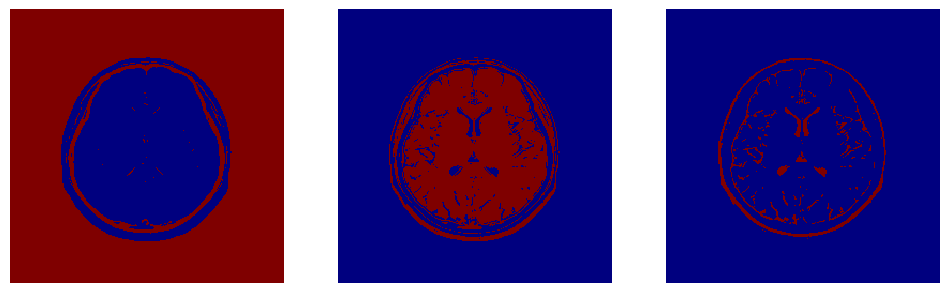

In [8]:
m_vals = np.array([64., 128, 192.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1
cmap = np.argmin(c,axis=-1)
while E>eps:
  print(m_vals)
  for i in range(len(m_vals)):
    c[:,:,i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c,axis=-1)

  for i in range(len(m_vals)):
    if np.any(cmap==i):
      m_vals_new[i] = np.mean(f[cmap==i])
    else:
      m_vals_new[i] = 0

  E = np.sum(np.abs(m_vals_new - m_vals))
  m_vals = m_vals_new.copy()

for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])
cmap = np.argmin(c, axis=-1)

print('최종 중심값:', m_vals)


plt.figure(figsize=(4 * len(m_vals), 4))

for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()

### k = 4 에서의 결과

[ 64. 128. 192. 256.]
[  5.91248043 127.4        193.0608365  786.23018812]
[  5.56957333 109.07602339 367.92850915 830.32965646]
[  5.48676927 137.96098105 502.37279236 916.69989937]
[  5.61385783 192.47203947 560.60638175 984.36501216]
[   5.96398793  244.75828313  593.83831175 1020.41990894]
[   6.26206558  287.34212261  618.22393896 1046.59942363]
[   6.56594164  325.928856    638.78432447 1069.83680732]
[   6.84303061  362.70790216  659.45681535 1093.998312  ]
[   7.1059246   400.65480558  682.93173009 1121.70193976]
[   7.42823321  440.73794038  713.30921465 1158.01787017]
[   7.8311066   483.18565797  757.38205276 1207.80176211]
[   8.30904844  514.42484132  806.70853909 1281.77067884]
[   8.75123185  533.8230234   843.78412432 1369.18549301]
[   8.97723077  545.05091553  865.99957411 1432.92703075]
[   9.15806813  552.64092971  880.04311649 1472.26721906]
[   9.19950371  556.96374889  888.4961757  1495.15239155]
[   9.27141603  559.58026847  893.00593994 1506.96997691]
[   9.30

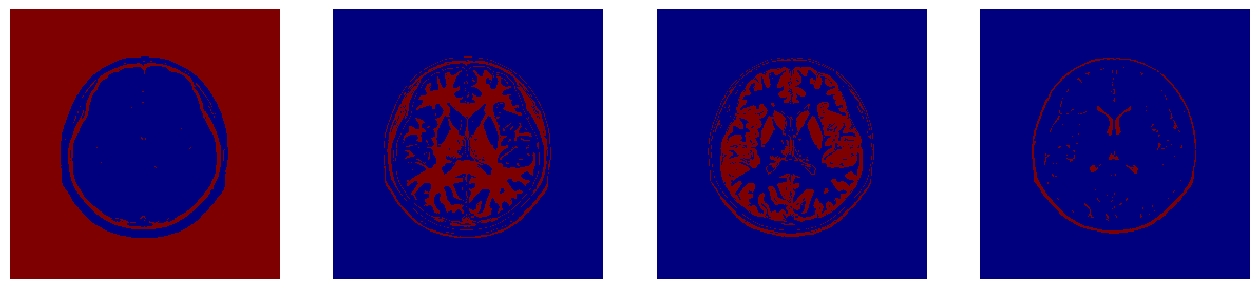

In [9]:
m_vals = np.array([64., 128, 192., 256.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1
cmap = np.argmin(c,axis=-1)
while E>eps:
  print(m_vals)
  for i in range(len(m_vals)):
    c[:,:,i] = np.abs(f - m_vals[i])

  cmap = np.argmin(c,axis=-1)

  for i in range(len(m_vals)):
    if np.any(cmap==i):
      m_vals_new[i] = np.mean(f[cmap==i])
    else:
      m_vals_new[i] = 0

  E = np.sum(np.abs(m_vals_new - m_vals))
  m_vals = m_vals_new.copy()

for i in range(len(m_vals)):
    c[:, :, i] = np.abs(f - m_vals[i])
cmap = np.argmin(c, axis=-1)

print('최종 중심값:', m_vals)


plt.figure(figsize=(4 * len(m_vals), 4))

for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()